In [ ]:
# import liabraries

import laspy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import MultiPoint
from sklearn.cluster import DBSCAN

In [ ]:
# load lidar file

number = 20

las_path = f"../data/processed_non_ground_sor/{number}kmh_pipeline_corridor_nonground_sor.las"

las = laspy.read(las_path)


points = np.column_stack(
    (
        np.array(las.x),
        np.array(las.y),
        np.array(las.z)
    )
)


print("Points:", points.shape)

Points: (338783, 3)


In [ ]:
# apply voxel downsampling


import open3d as o3d
import numpy as np


pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(points)


voxel_size = 0.1   # 10 cm


pcd_down = pcd.voxel_down_sample(
    voxel_size
)


points = np.asarray(
    pcd_down.points
)


print(points.shape)

(230680, 3)


In [ ]:
# apply DBSCAN clustering

db = DBSCAN(
    eps=0.9,
    min_samples=30,
    n_jobs=-1
)


labels = db.fit_predict(
    points
)


print("Clusters:", len(set(labels)))

Clusters: 278


In [ ]:
print("First cluster ID:", labels.min())

print("Last cluster ID:", labels.max())

First cluster ID: -1
Last cluster ID: 276


In [ ]:
# check shape of points and labels of clusters

print(points.shape)
print(labels.shape)

(213710, 3)
(213710,)


In [ ]:
# check number of unique clusters ids and points 


unique, counts = np.unique(
    labels,
    return_counts=True
)

cluster_info = sorted(
    zip(unique, counts),
    key=lambda x: x[1],
    reverse=True
)

for cluster, size in cluster_info[:20]:
    print(cluster, size)

4 19716
5 15293
21 13614
0 11231
-1 10953
1 8932
14 8532
9 6873
2 4801
29 4389
56 4068
11 3833
37 3706
17 3703
23 3215
8 2978
41 2890
25 2713
10 2630
18 2459


In [ ]:
# calculate noise points and noise percentage

noise_points = np.sum(labels == -1)

print(
    "Noise points:",
    noise_points
)

print(
    "Noise percentage:",
    noise_points / len(labels) * 100
)

Noise points: 10953
Noise percentage: 5.125169622385475


In [ ]:


sizes = counts[unique != -1]

print("Clusters < 50 points:",
      np.sum(sizes < 50))

print("Clusters < 100 points:",
      np.sum(sizes < 100))

Clusters < 50 points: 68
Clusters < 100 points: 131


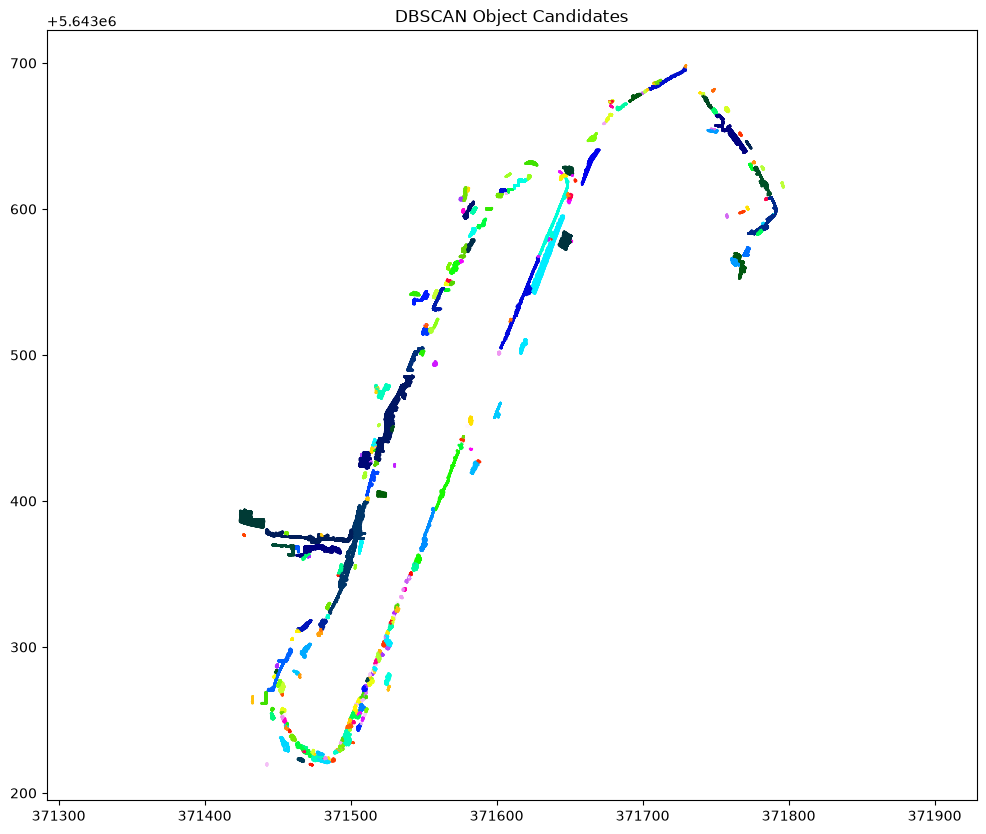

In [ ]:
# plot DBSCAN object candiadtes or clusters

mask = labels != -1

fig, ax = plt.subplots(figsize=(12,10))

ax.scatter(
    points[mask,0],
    points[mask,1],
    c=labels[mask],
    s=0.5,
    cmap="gist_ncar"
)

ax.axis("equal")
ax.set_title("DBSCAN Object Candidates")

plt.show()


# Save limits
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

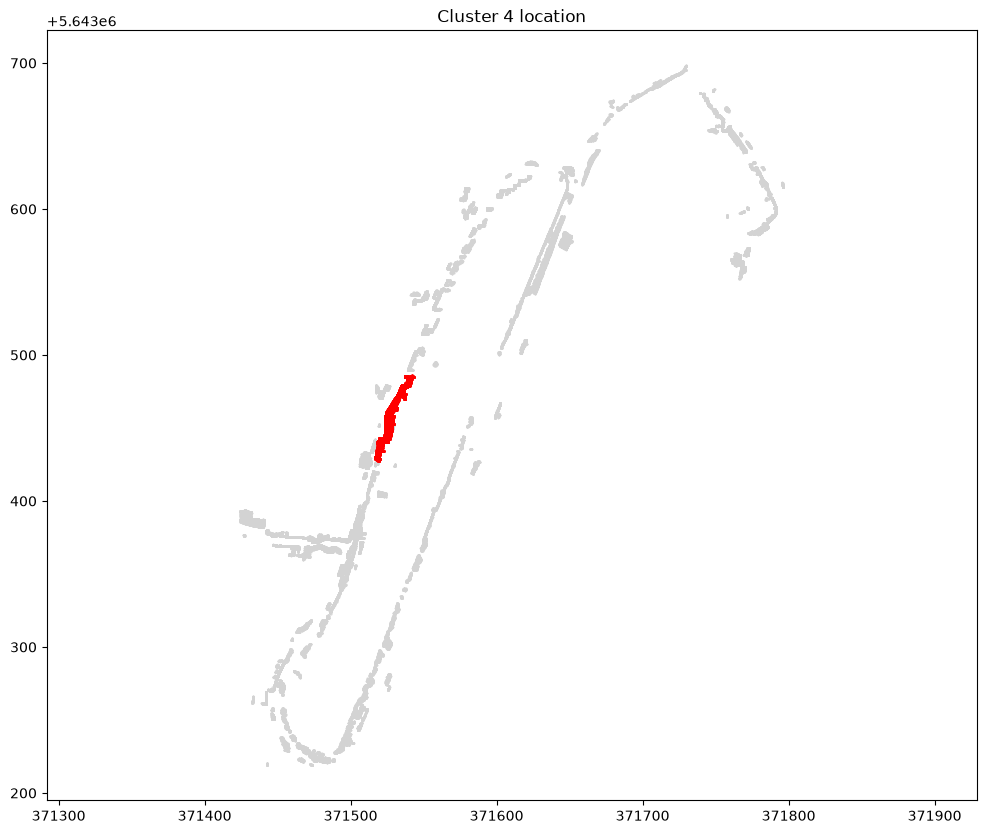

In [ ]:
# plot specific DBSCAN object candiadte or cluster 


cluster_id = 4

cluster_mask = labels == cluster_id


fig, ax = plt.subplots(figsize=(12,10))


# All points in grey
ax.scatter(
    points[mask,0],
    points[mask,1],
    s=0.2,
    c="lightgrey"
)


# Selected cluster
ax.scatter(
    points[cluster_mask,0],
    points[cluster_mask,1],
    s=1,
    c="red"
)


ax.set_xlim(x_limits)
ax.set_ylim(y_limits)

ax.axis("equal")
ax.set_title(f"Cluster {cluster_id} location")

plt.show()

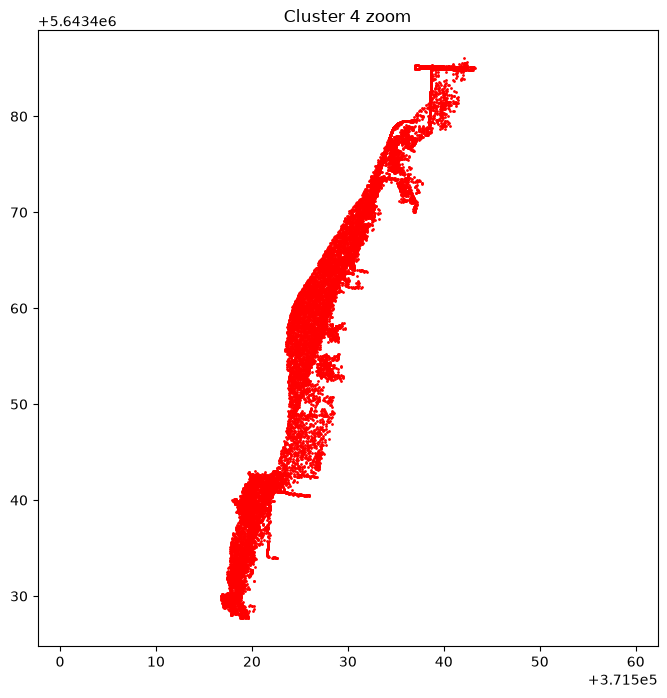

In [ ]:
# plot specific cluster top view


cluster_points = points[cluster_mask]


plt.figure(figsize=(8,8))

plt.scatter(
    cluster_points[:,0],
    cluster_points[:,1],
    s=1,
    c= 'red'
)


plt.axis("equal")
plt.title(f"Cluster {cluster_id} zoom")

plt.show()

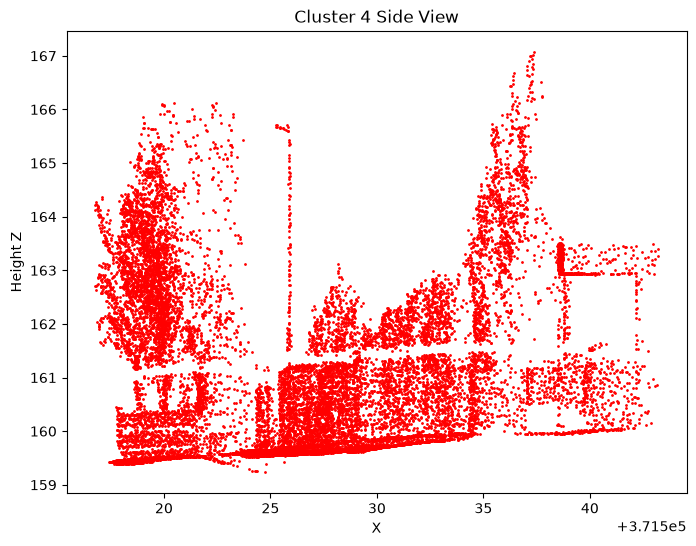

In [ ]:
# plot specific cluster side view


plt.figure(figsize=(8,6))

plt.scatter(
    cluster_points[:,0],
    cluster_points[:,2],
    s=1,
    c= 'red'
)

plt.xlabel("X")
plt.ylabel("Height Z")
plt.title(f"Cluster {cluster_id} Side View")

plt.show()

In [132]:
print(
    "Height:",
    cluster_points[:,2].max()-cluster_points[:,2].min()
)

Height: 8.369


In [ ]:
# get only label where where min samples are more than 100

min_cluster_size = 100

valid_clusters = [
    c for c in np.unique(labels)
    if c != -1 and np.sum(labels == c) >= min_cluster_size
]

print("Valid objects:", len(valid_clusters))

Valid objects: 146


In [ ]:
# get only label where where min samples are more than 100 and save points and lables for it

min_cluster_size = 100

valid_clusters = []

for c in np.unique(labels):
    if c == -1:
        continue

    count = np.sum(labels == c)

    if count >= min_cluster_size:
        valid_clusters.append(c)


# Create mask for clusters >= 100 points
mask = np.isin(labels, valid_clusters)


# Save filtered points and labels
dbscan_points_filtered = points[mask]
dbscan_labels_filtered = labels[mask]


np.save(
    "../data/csv/20dbscan_points_min100.npy",
    dbscan_points_filtered
)

np.save(
    "../data/csv/20dbscan_labels_min100.npy",
    dbscan_labels_filtered
)


print("Points saved:", dbscan_points_filtered.shape)
print("Labels saved:", dbscan_labels_filtered.shape)

Points saved: (214033, 3)
Labels saved: (214033,)


In [ ]:


min_cluster_size = 100


cluster_ids = []

for c in np.unique(labels):
    
    if c == -1:
        continue
        
    count = np.sum(labels == c)
    
    if count >= min_cluster_size:
        cluster_ids.append(c)


print("Clusters used:", len(cluster_ids))

Clusters used: 18


In [ ]:
# calculate and save attrubutes in features

features = []


for cluster_id in cluster_ids:

    mask = labels == cluster_id
    
    cluster = points[mask]


    # Number of points
    n_points = len(cluster)


    # Bounding box dimensions

    width = (
        cluster[:,0].max() -
        cluster[:,0].min()
    )

    length = (
        cluster[:,1].max() -
        cluster[:,1].min()
    )

    height = (
        cluster[:,2].max() -
        cluster[:,2].min()
    )


    # Center position

    center_x = np.mean(cluster[:,0])
    center_y = np.mean(cluster[:,1])
    center_z = np.mean(cluster[:,2])


    # Volume approximation

    volume = width * length * height


    # Point density

    density = n_points / volume if volume > 0 else 0


    features.append(
        [
            cluster_id,
            n_points,
            width,
            length,
            height,
            volume,
            density,
            center_x,
            center_y,
            center_z
        ]
    )

In [ ]:
# convert the fetures in pandas dataframe


feature_df = pd.DataFrame(
    features,
    columns=[
        "cluster_id",
        "points",
        "width",
        "length",
        "height",
        "volume",
        "density",
        "center_x",
        "center_y",
        "center_z"
    ]
)


feature_df.head()

,cluster_id,points,width,length,height,volume,density,center_x,center_y,center_z
0,0,9162,4.985000,13.4240,3.948000,264.194791,34.678958,371767.629003,5.643558e+06,153.909794
1,1,21107,14.669000,23.5080,13.578000,4682.221932,4.507903,371781.446568,5.643620e+06,160.388738
2,2,7314,10.838000,13.8157,6.410974,959.944302,7.619192,371767.708256,5.643642e+06,161.070582
3,3,536,2.843182,3.4850,1.254500,12.430199,43.120790,371780.731601,5.643584e+06,154.361737
4,4,1282,5.863000,3.1220,5.214000,95.438547,13.432728,371782.842363,5.643606e+06,159.444175


In [ ]:
# load underground pipeline data

hal_path = "../data/leitungen/HAL.shp"
vl_path = "../data/leitungen/VL.shp"

hal = gpd.read_file(hal_path)
vl = gpd.read_file(vl_path)

print("HAL CRS:", hal.crs)
print("VL CRS:", vl.crs)

HAL CRS: EPSG:25832
VL CRS: EPSG:25832


In [ ]:
# change cordinates system


target_crs = "EPSG:32632"

hal = hal.to_crs(target_crs)
vl = vl.to_crs(target_crs)


print("HAL CRS:", hal.crs)
print("VL CRS:", vl.crs)

HAL CRS: EPSG:32632
VL CRS: EPSG:32632


In [ ]:
# Combine HAL + VL

pipelines = pd.concat([hal, vl], ignore_index=True)

print("Total pipeline segments:", len(pipelines))

Total pipeline segments: 36


In [25]:
from shapely.ops import unary_union

pipeline_union = unary_union(pipelines.geometry)

In [26]:
type(pipeline_union)

shapely.geometry.multilinestring.MultiLineString

In [ ]:
# calculate min distance of pipelines from the clutsers

cluster_geometries = []
min_distances = []

for cluster_id in cluster_ids:

    mask = labels== cluster_id

    cluster_xy = points[mask][:, :2]

    hull = MultiPoint(cluster_xy).convex_hull

    cluster_geometries.append(hull)

    min_distances.append(
        hull.distance(pipeline_union)
    )

feature_df["geometry"] = cluster_geometries
feature_df["min_distance_pipeline"] = min_distances

In [28]:
feature_df["min_distance_pipeline"].min()

np.float64(0.0)

In [ ]:
# calculate risk based on min distance of pipelines from the clutsers


def risk(distance):

    if distance < 2:
        return "High"

    elif distance < 5:
        return "Medium"

    else:
        return "Low"


feature_df["pipeline_risk"] = (
    feature_df["min_distance_pipeline"]
    .apply(risk)
)

In [30]:
feature_df["pipeline_risk"].value_counts()

pipeline_risk
High      12
Medium     6
Name: count, dtype: int64

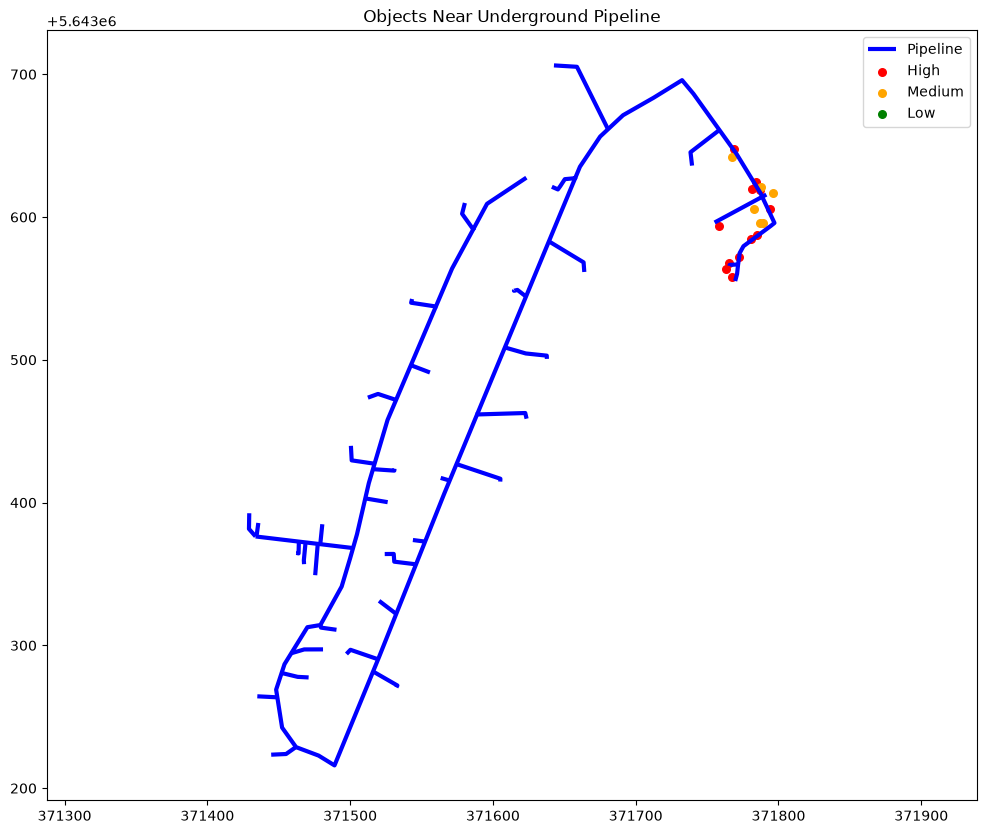

In [ ]:
# plot the risk vs the pipleine 

fig, ax = plt.subplots(figsize=(12,10))


# Pipeline
pipelines.plot(
    ax=ax,
    color="blue",
    linewidth=3,
    label="Pipeline"
)


# Clusters
for risk, color in [
    ("High","red"),
    ("Medium","orange"),
    ("Low","green")
]:

    subset = feature_df[
        feature_df["pipeline_risk"] == risk
    ]

    ax.scatter(
        subset["center_x"],
        subset["center_y"],
        c=color,
        s=30,
        label=risk
    )


ax.legend()
ax.axis("equal")
plt.title("Objects Near Underground Pipeline")

plt.show()

In [ ]:
# save the new features to csv

feature_df.to_csv(
    "../data/csv/40kmh_object_features.csv",
    index=False
)

In [47]:
feature_df.head()

,cluster_id,points,width,length,height,volume,density,center_x,center_y,center_z,geometry,min_distance_pipeline,pipeline_risk
0,0,3997,9.858,7.4685,10.552,776.885439,5.144903,371468.319682,5.643314e+06,161.740782,"POLYGON ((371463.42 5643310.8040000005, 371463...",0.749214,High
1,1,18187,59.416,9.1460,8.356,4540.806958,4.005235,371478.147537,5.643375e+06,163.908360,"POLYGON ((371477.24 5643371.578, 371474.14 564...",0.000000,High
2,2,11910,24.934,6.2690,11.984,1873.233972,6.357988,371479.887420,5.643368e+06,163.387076,"POLYGON ((371468.515 5643363.587, 371468.349 5...",0.000000,High
3,3,365,1.595,1.7040,5.470,14.866804,24.551343,371551.429356,5.643520e+06,162.173417,"POLYGON ((371551.945 5643519.11, 371551.205 56...",0.304188,High
4,4,12701,20.937,25.9010,6.361,3449.501837,3.681981,371761.462822,5.643650e+06,161.224565,"POLYGON ((371768.493 5643638.5770000005, 37176...",0.000000,High
